### Preparing the Data

In [1]:
import glob
import os
import string
import unicodedata
from io import open

all_letters = string.ascii_letters + " ,;'-"
n_letters = len(all_letters) + 1  # For EOS marker


def find_files(path):
    return glob.glob(path)  # noqa: PTH207


# Turn a Unicode string to plain ASCII string
def unicode_to_ascii(s):
    return "".join(
        c
        for c in unicodedata.normalize("NFD", s)
        if unicodedata.category(c) != "Mn" and c in all_letters
    )


# Read a file and split into lines
def read_lines(filename):
    with open(filename, encoding="utf-8") as somefile:  # noqa: UP020
        return [unicode_to_ascii(line.strip()) for line in somefile]


# Build the category_lines dictionary, a list of lines per category
category_lines = {}
all_categories = []

for filename in find_files("char_rnn_data/names/*.txt"):
    category = os.path.splitext(os.path.basename(filename))[0]  # noqa: PTH119, PTH122
    lines_list = read_lines(filename)
    all_categories.append(category)
    category_lines[category] = lines_list

n_categories = len(all_categories)

if n_categories == 0:
    raise RuntimeError("Data Not Found! Make sure to download the data.")

print("# categories: ", n_categories, all_categories)
print(unicode_to_ascii("O'Néàl"))


# categories:  18 ['Czech', 'German', 'Arabic', 'Japanese', 'Chinese', 'Vietnamese', 'Russian', 'French', 'Irish', 'English', 'Spanish', 'Greek', 'Italian', 'Portuguese', 'Scottish', 'Dutch', 'Korean', 'Polish']
O'Neal


### Creating the Network

<p align="center">
    <img src="assets/rnn_network_char_gen.png" width="400" height="400" alt="Network Architecture" >
</p>


In [2]:
import torch
from torch import nn


class RNN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.hidden_size = hidden_size

        self.i2h = nn.Linear(n_categories + input_size + hidden_size, hidden_size)
        self.i2o = nn.Linear(n_categories + input_size + hidden_size, output_size)
        self.o2o = nn.Linear(output_size + hidden_size, output_size)

        self.dropout = nn.Dropout(0.1)
        self.softmax = nn.LogSoftmax(dim=1)

    def forward(self, category, input, hidden):  # noqa: A002
        input_combined = torch.cat((category, input, hidden), 1)
        hidden_state = self.i2h(input_combined)
        output = self.i2o(input_combined)
        output_combined = torch.cat((hidden_state, output), 1)
        output = self.o2o(output_combined)
        output = self.dropout(output)
        output = self.softmax(output)

        return output, hidden_state

    def init_hidden(self):
        return torch.zeros(1, self.hidden_size)


### Training

#### Preparing for Training

In [3]:
# helper functions to get random pairs of (category, line):
import random


# Random item from a list
def random_choice(items):
    return items[random.randint(0, len(items) - 1)]


# Get a random category and random line from that category
def random_training_pair():
    category = random_choice(all_categories)
    line = random_choice(category_lines[category])
    return category, line


In [4]:
# one-hot vector for category
def category_to_tensor(category):
    tensor = torch.zeros(1, n_categories)
    index = all_categories.index(category)
    tensor[0][index] = 1
    return tensor


# One-hot matrix of first to last letters (not including EOS) for input
def input_tensor(line):
    tensor = torch.zeros(len(line), 1, n_letters)
    for i in range(len(line)):
        index = all_letters.find(line[i])
        tensor[i][0][index] = 1

    return tensor


# ``LongTensor`` of second letter to end (EOS) for target
def target_tensor(line):
    letter_indexes = [all_letters.find(line[i]) for i in range(1, len(line))]
    letter_indexes.append(n_letters - 1)  # For EOS index

    return torch.LongTensor(letter_indexes)


In [5]:
target_tensor("Miyazaki")


tensor([ 8, 24,  0, 25,  0, 10,  8, 57])

In [6]:
# Make category, input, and target tensors from a random category, line pair
def random_training_example():
    category, line = random_training_pair()
    category_tensor = category_to_tensor(category)
    input_line_tensor = input_tensor(line)
    output_target_tensor = target_tensor(line)

    return category_tensor, input_line_tensor, output_target_tensor


### Training the Network

In [7]:
rnn = RNN(n_letters, 128, n_letters)


In [8]:
input_tensor("ANA").size(dim=0)


3

In [12]:
criterion = nn.NLLLoss()

learning_rate = 0.001

def train(category_tensor, input_line_tensor, output_target_tensor):
    output_target_tensor.unsqueeze_(-1)
    hidden = rnn.init_hidden()

    rnn.zero_grad()

    loss = torch.zeros(1) # or: torch.tensor([0.0])

    for i in range(input_line_tensor.size(0)):
        output, hidden = rnn(category_tensor, input_line_tensor[i], hidden)
        temp_loss = criterion(output, output_target_tensor[i])
        loss += temp_loss

    loss.backward()

    for p in rnn.parameters():
        p.data.add_(p.grad.data, alpha=-learning_rate)

    return output, loss.item() / input_line_tensor.size(0)


In [13]:
import math
import time


def time_since(since):
    now = time.time()
    s = now - since
    m = math.floor(s / 60)
    s -= m * 60
    return f"{m}m {s:.0f}s"


In [14]:
n_iterations = 100000
print_every = 5000
plot_every = 500
all_losses = []
total_loss = 0  # Reset every ``plot_every`` ``iters``

start = time.time()

for n_iter in range(1, n_iterations+1):
    output, loss = train(*random_training_example())
    total_loss += loss

    if n_iter % print_every == 0:
        print(f"{time_since(start)} {n_iter} {n_iter / n_iterations * 100}% \t loss = {loss}")

    if n_iter % plot_every == 0:
        all_losses.append(total_loss / plot_every)
        total_loss = 0


0m 7s 5000 5.0 	 loss = 2.9595494951520647
0m 14s 10000 10.0 	 loss = 2.504748753138951
0m 20s 15000 15.0 	 loss = 2.6003662745157876
0m 27s 20000 20.0 	 loss = 2.7931038538614907
0m 34s 25000 25.0 	 loss = 1.7582378387451172
0m 40s 30000 30.0 	 loss = 1.0465741157531738
0m 47s 35000 35.0 	 loss = 1.6087478399276733
0m 53s 40000 40.0 	 loss = 1.9741050720214843
1m 0s 45000 45.0 	 loss = 2.213439146677653
1m 7s 50000 50.0 	 loss = 2.3230957984924316
1m 14s 55000 55.00000000000001 	 loss = 2.764816474914551
1m 21s 60000 60.0 	 loss = 2.39223575592041
1m 27s 65000 65.0 	 loss = 2.4529733657836914
1m 34s 70000 70.0 	 loss = 2.8531532287597656
1m 40s 75000 75.0 	 loss = 2.542331271701389
1m 47s 80000 80.0 	 loss = 2.344839413960775
1m 54s 85000 85.0 	 loss = 2.065777540206909
2m 0s 90000 90.0 	 loss = 3.021839141845703
2m 7s 95000 95.0 	 loss = 2.1801736831665037
2m 13s 100000 100.0 	 loss = 3.0758109092712402


### Plotting the Losses


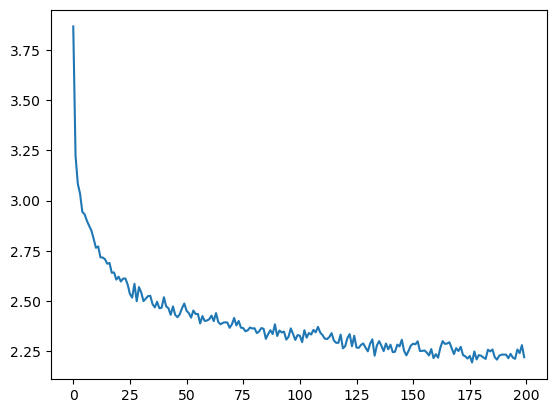

In [15]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(all_losses)


### Sampling the Network

In [17]:
max_length = 20

# Sample from a category and starting letter
def sample(category, start_letter='A'):
    with torch.no_grad():
        category_tensor = category_to_tensor(category)
        input_letter_tensor = input_tensor(start_letter)
        hidden = rnn.init_hidden()

        output_name = start_letter
        for i in range(max_length):
            output, hidden = rnn(category_tensor, input_letter_tensor[0], hidden)
            topv, topi = output.topk(1)
            topi = topi[0][0]

            if topi == n_letters -1:
                break
            letter = all_letters[topi]
            output_name += letter
            input_letter_tensor = input_tensor(letter)

        return output_name

# Get multiple samples from one category and multiple starting letters
def samples(category, start_letters = "ANY"):
    for start_letter in start_letters:
        print(sample(category, start_letter))


In [24]:
samples(category="Japanese", start_letters="YKO")


Yaki
Kaka
O'koutai


In [25]:
samples("English", start_letters="JLP")


Jandello
Lamello
Pandel


In [26]:
samples(category="Arabic", start_letters="RSA")


Rama
Samar
Abara


In [27]:
samples(category="Chinese", start_letters="LYM")


Lin
Yin
Man
